# Proyecto Final #1 - Transfer Learning con SAM2
## Segmentacion Semantica Multiclase - SuperTuxKart

**Universidad San Francisco de Quito**
**Vision Artificial 202610**


Se utiliza el encoder de SAM 2 como backbone congelado
y se entrena un decoder personalizado para segmentacion semantica de 7 clases:

| Clase | Valor |
|---|---|
| Background | 0 |
| Track | 1 |
| Kart | 2 |
| Pickup | 3 |
| Nitro | 4 |
| Bomb | 5 |
| Projectile | 6 |

In [1]:
import sys
!{sys.executable} -m pip install torch torchvision transformers matplotlib numpy pillow


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python3.10 -m pip install --upgrade pip


## 1. Imports y Configuracion

In [2]:
import os
import sys
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Subset, WeightedRandomSampler
from transformers import Sam2Model

from utils import (
    SuperTuxKartDataset, create_dataloaders,
    compute_iou, compute_iou_per_class,
    denormalize, mask_to_color, show_samples, show_predictions,
    explore_class_distribution,
    NUM_CLASSES, CLASS_NAMES, COLORS, DEVICE, IMG_SIZE, BATCH_SIZE
)

# Hiperparametros
EPOCHS = 60
LR = 5e-4
DATASET_PATH = os.path.join(os.getcwd(), "seg_dataset")

print(f"Device: {DEVICE}")
print(f"Dataset: {DATASET_PATH}")
print(f"Clases: {NUM_CLASSES} -> {CLASS_NAMES}")
print(f"Imagen: {IMG_SIZE}, Batch: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}, LR: {LR}")

/opt/homebrew/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps
Dataset: /Users/pabloencalada/Downloads/Proyecto Final #1 - Transfer Learning SAM/seg_dataset
Clases: 7 -> ['Background', 'Track', 'Kart', 'Pickup', 'Nitro', 'Bomb', 'Projectile']
Imagen: (512, 512), Batch: 4
Epochs: 60, LR: 0.0005


## 2. Exploracion del Dataset

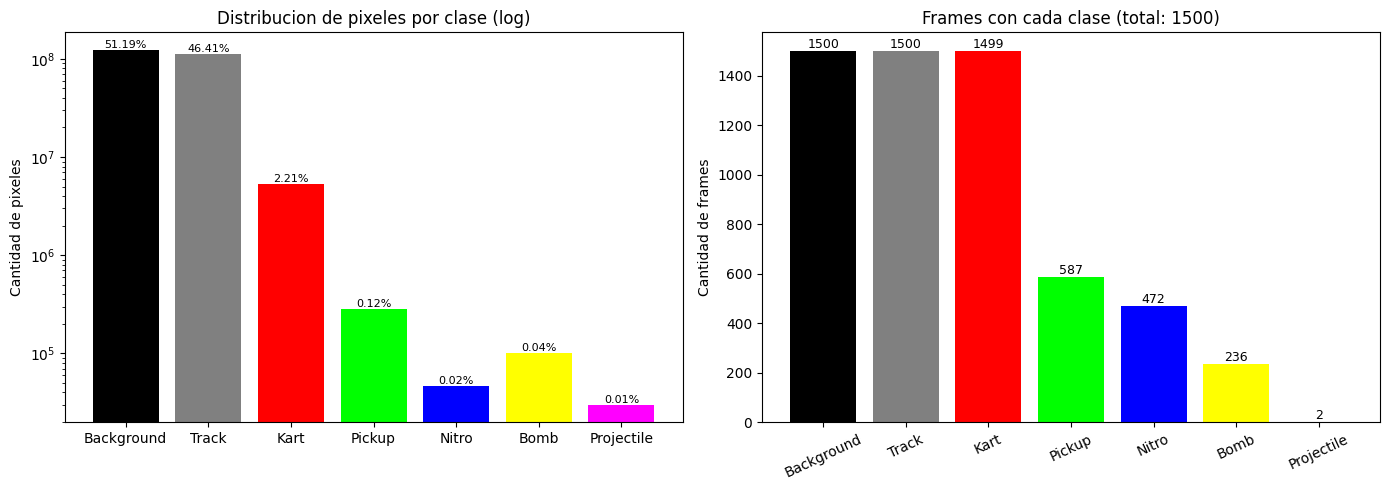


Distribucion de pixeles:
  Background  :  122,844,679 (51.19%)
  Track       :  111,387,780 (46.41%)
  Kart        :    5,304,448 (2.21%)
  Pickup      :      286,119 (0.12%)
  Nitro       :       46,899 (0.02%)
  Bomb        :      100,058 (0.04%)
  Projectile  :       30,017 (0.01%)

Frames con cada clase:
  Background  : 1500
  Track       : 1500
  Kart        : 1499
  Pickup      : 587
  Nitro       : 472
  Bomb        : 236
  Projectile  : 2


In [3]:
explore_class_distribution(DATASET_PATH)

Como podemos observar existe un desbalanceo muy grande en el dataset. Background y Track juntos representan más del 90% de los píxeles, mientras que Nitro, Bomb y Projectile son menos del 0.5%. Si entrenamos sin tomar esto en cuenta, el modelo va a aprender a predecir solo Background y Track con un accuracy alto, pero no serviría para detectar los objetos pequeños.

Además, Projectile aparece en muy pocos frames (prácticamente inexistente), lo cual hace casi imposible que el modelo aprenda esa clase. Aún así la mantenemos en el modelo con 7 clases como pide el enunciado.

Para combatir el desbalance vamos a usar oversampling para darle más peso a los frames que contienen clases raras, pesos en CrossEntropyLoss para penalizar más los errores en clases poco frecuentes, y Dice Loss que mide overlap por clase para que las clases pequeñas también importen en el loss.

Dataset cargado: 1500 muestras desde /Users/pabloencalada/Downloads/Proyecto Final #1 - Transfer Learning SAM/seg_dataset


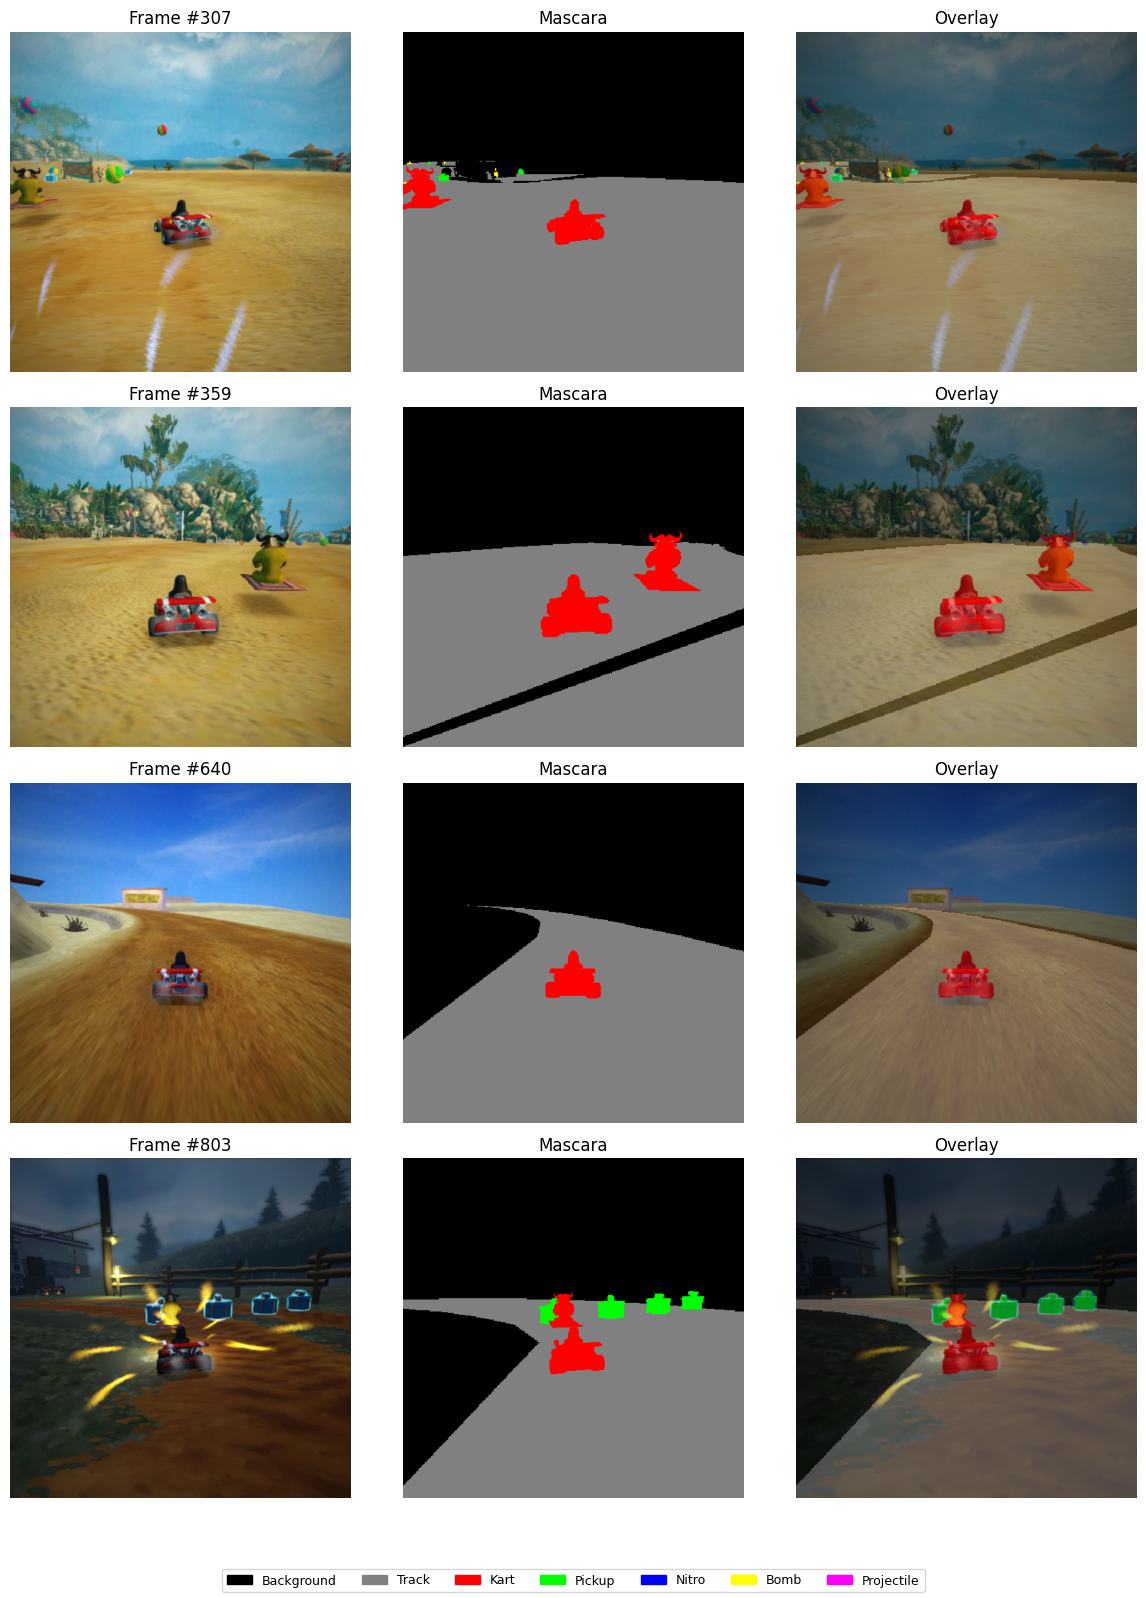

In [4]:
dataset_preview = SuperTuxKartDataset(DATASET_PATH, img_size=IMG_SIZE, augment=False)
show_samples(dataset_preview, num_samples=4)

Para el dataset redimensionamos las imágenes de 400x400 a 512x512. Aplicamos data augmentation en entrenamiento como flips horizontales, rotación y cambios de brillo, contraste y saturación, etc. La normalización usa los valores estándar de ImageNet ya que el encoder de SAM2 fue pre-entrenado con esa normalización.

## 3. DataLoaders

In [5]:
train_loader, val_loader = create_dataloaders(
    DATASET_PATH, img_size=IMG_SIZE, batch_size=BATCH_SIZE, val_split=0.2, seed=42
)

images, masks = next(iter(train_loader))
print(f"\nBatch shapes -> images: {images.shape}, masks: {masks.shape}")
print(f"Mask values range: [{masks.min().item()}, {masks.max().item()}]")

Dataset cargado: 1500 muestras desde /Users/pabloencalada/Downloads/Proyecto Final #1 - Transfer Learning SAM/seg_dataset
Dataset cargado: 1500 muestras desde /Users/pabloencalada/Downloads/Proyecto Final #1 - Transfer Learning SAM/seg_dataset
Train: 1200 muestras (300 batches)
  - Con clases raras: 536 (peso 5x)
  - Sin clases raras: 664 (peso 1x)
Val:   300 muestras (75 batches)

Batch shapes -> images: torch.Size([4, 3, 512, 512]), masks: torch.Size([4, 512, 512])
Mask values range: [0, 5]


Usamos un split 80/20 para train/validación con seed fija para reproducibilidad. El batch size es de 4 porque el encoder de SAM2 consume más memoria al procesar.

El WeightedRandomSampler le da 5x más probabilidad de aparecer a los frames que contienen Nitro, Bomb o Projectile. De los 1200 frames de train, 536 tienen clases raras, así que con el oversampling el modelo las ve mucho más seguido y no las ignora.

## 4. Modelo: SAM2 Encoder + Segmentation Decoder

Para e transfer learning vamos a cargar el modelo SAM2 pre entrenado y congelar sus pesos. Luego usaremos sus features FPN para entrenar un decider ligero que combine estos y nos de la segmentacion de las 7 clases posiblemente. Aunque nos anticipamos a que al menos Projectile no obtenga tan buenos resultados.

In [6]:
class SegmentationDecoder(nn.Module):
    """Decoder que toma features FPN multiescala y produce segmentacion.
    
    Recibe 3 niveles FPN de 256 canales cada uno y los fusiona
    progresivamente con upsampling para producir un mapa de segmentacion.
    """
    def __init__(self, fpn_channels=256, num_classes=7):
        super().__init__()
        # Procesar cada nivel FPN
        self.conv_high = nn.Sequential(
            nn.Conv2d(fpn_channels, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.conv_mid = nn.Sequential(
            nn.Conv2d(fpn_channels, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.conv_low = nn.Sequential(
            nn.Conv2d(fpn_channels, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        
        # Fusion: combinar los 3 niveles (128*3 = 384 canales)
        self.fuse = nn.Sequential(
            nn.Conv2d(384, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        
        # Cabeza de clasificacion
        self.classifier = nn.Conv2d(128, num_classes, 1)
    
    def forward(self, fpn_features):
        # fpn_features: list of 3 tensors
        # [0]: alta res (B, 256, H/4, W/4)
        # [1]: media res (B, 256, H/8, W/8)  
        # [2]: baja res (B, 256, H/16, W/16)
        high, mid, low = fpn_features
        target_size = high.shape[2:]  # usar la resolucion mas alta como referencia
        
        high = self.conv_high(high)
        mid = self.conv_mid(F.interpolate(mid, size=target_size, mode='bilinear', align_corners=False))
        low = self.conv_low(F.interpolate(low, size=target_size, mode='bilinear', align_corners=False))
        
        fused = torch.cat([high, mid, low], dim=1)  # (B, 384, H/4, W/4)
        fused = self.fuse(fused)  # (B, 128, H/4, W/4)
        out = self.classifier(fused)  # (B, num_classes, H/4, W/4)
        return out


class SAM2Segmenter(nn.Module):
    """SAM2 encoder (congelado) + decoder de segmentacion (entrenable)."""
    
    def __init__(self, model_name='facebook/sam2.1-hiera-tiny', num_classes=7):
        super().__init__()
        print(f"Cargando SAM2 encoder: {model_name}...")
        sam2 = Sam2Model.from_pretrained(model_name)
        self.encoder = sam2.vision_encoder
        
        # Congelar encoder completamente
        for param in self.encoder.parameters():
            param.requires_grad = False
        
        self.decoder = SegmentationDecoder(fpn_channels=256, num_classes=num_classes)
        
        enc_params = sum(p.numel() for p in self.encoder.parameters())
        dec_params = sum(p.numel() for p in self.decoder.parameters())
        print(f"Encoder params (congelados): {enc_params:,}")
        print(f"Decoder params (entrenables): {dec_params:,}")
    
    def forward(self, x):
        # x: (B, 3, H, W)
        with torch.no_grad():
            enc_out = self.encoder(x)
        
        fpn_features = list(enc_out.fpn_hidden_states)  # 3 niveles multiescala
        logits = self.decoder(fpn_features)  # (B, num_classes, H/4, W/4)
        
        # Upsample a resolucion original
        logits = F.interpolate(logits, size=x.shape[2:], mode='bilinear', align_corners=False)
        return logits


# Instanciar el modelo
model = SAM2Segmenter(num_classes=NUM_CLASSES).to(DEVICE)

# Verificar shapes
with torch.no_grad():
    test_in = torch.randn(1, 3, *IMG_SIZE).to(DEVICE)
    test_out = model(test_in)
    print(f"\nInput:  {test_in.shape}")
    print(f"Output: {test_out.shape} ({NUM_CLASSES} clases)")

Cargando SAM2 encoder: facebook/sam2.1-hiera-tiny...


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
Loading weights: 100%|██████████| 309/309 [00:00<00:00, 7223.01it/s]


Encoder params (congelados): 27,219,136
Decoder params (entrenables): 2,067,591

Input:  torch.Size([1, 3, 512, 512])
Output: torch.Size([1, 7, 512, 512]) (7 clases)


## 5. Entrenamiento
Como funcion de perdida usaremos CrossEntropyLoss y Dice Loss para mejorar segmentacion de clases pequenas.

In [7]:
class DiceLoss(nn.Module):
    """Dice Loss multiclase - mide overlap entre prediccion y ground truth."""
    def __init__(self, num_classes=NUM_CLASSES, smooth=1.0):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)
        targets_one_hot = F.one_hot(targets, self.num_classes).permute(0, 3, 1, 2).float()
        dims = (0, 2, 3)
        intersection = (probs * targets_one_hot).sum(dim=dims)
        cardinality = probs.sum(dim=dims) + targets_one_hot.sum(dim=dims)
        dice_score = (2.0 * intersection + self.smooth) / (cardinality + self.smooth)
        return 1.0 - dice_score.mean()


class CombinedLoss(nn.Module):
    """30% CrossEntropy (con pesos) + 70% Dice Loss."""
    def __init__(self, class_weights, ce_weight=0.3, dice_weight=0.7):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights)
        self.dice = DiceLoss()
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        return self.ce_weight * self.ce(logits, targets) + self.dice_weight * self.dice(logits, targets)


# Pesos inversamente proporcionales a la frecuencia de cada clase
class_weights = torch.tensor([0.5, 0.8, 3.0, 5.0, 8.0, 10.0, 15.0], dtype=torch.float32).to(DEVICE)
criterion = CombinedLoss(class_weights).to(DEVICE)
optimizer = torch.optim.Adam(model.decoder.parameters(), lr=LR)  # solo entrenamos el decoder
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=5, factor=0.5
)

print(f"Loss: 30% CrossEntropyLoss (con pesos) + 70% DiceLoss")
print(f"Optimizer: Adam (lr={LR}) - solo decoder")
print(f"Scheduler: ReduceLROnPlateau (patience=5, factor=0.5)")

Loss: 30% CrossEntropyLoss (con pesos) + 70% DiceLoss
Optimizer: Adam (lr=0.0005) - solo decoder
Scheduler: ReduceLROnPlateau (patience=5, factor=0.5)


In [8]:
best_iou = 0.0
history = {"train_loss": [], "val_loss": [], "val_iou": [], "lr": []}

for epoch in range(EPOCHS):
    # --- Train ---
    model.train()
    # Encoder siempre en eval (BatchNorm congelado)
    model.encoder.eval()
    running_loss = 0.0
    
    for images, masks in train_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    train_loss = running_loss / len(train_loader)
    
    # --- Validacion ---
    model.eval()
    val_running_loss = 0.0
    val_iou_sum = 0.0
    val_batches = 0
    
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            outputs = model(images)
            val_running_loss += criterion(outputs, masks).item()
            preds = outputs.argmax(dim=1).cpu()
            val_iou_sum += compute_iou(preds, masks.cpu())
            val_batches += 1
    
    val_loss = val_running_loss / len(val_loader)
    val_iou = val_iou_sum / val_batches
    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step(val_loss)
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["lr"].append(current_lr)
    
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), "model.th")
    
    if (epoch + 1) % 2 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val mIoU: {val_iou:.4f} | LR: {current_lr:.6f}")

print(f"\nEntrenamiento completado! Mejor mIoU: {best_iou:.4f}")
print(f"Modelo guardado en model.th")

Epoch   1/60 | Train Loss: 0.5749 | Val Loss: 0.4811 | Val mIoU: 0.5054 | LR: 0.000500
Epoch   2/60 | Train Loss: 0.4603 | Val Loss: 0.4379 | Val mIoU: 0.5360 | LR: 0.000500
Epoch   4/60 | Train Loss: 0.3894 | Val Loss: 0.3813 | Val mIoU: 0.6299 | LR: 0.000500
Epoch   6/60 | Train Loss: 0.3613 | Val Loss: 0.3654 | Val mIoU: 0.6097 | LR: 0.000500
Epoch   8/60 | Train Loss: 0.3517 | Val Loss: 0.3491 | Val mIoU: 0.5633 | LR: 0.000500
Epoch  10/60 | Train Loss: 0.3308 | Val Loss: 0.3301 | Val mIoU: 0.6605 | LR: 0.000500
Epoch  12/60 | Train Loss: 0.3201 | Val Loss: 0.3291 | Val mIoU: 0.6719 | LR: 0.000500
Epoch  14/60 | Train Loss: 0.2941 | Val Loss: 0.1975 | Val mIoU: 0.7287 | LR: 0.000500
Epoch  16/60 | Train Loss: 0.2288 | Val Loss: 0.1999 | Val mIoU: 0.7204 | LR: 0.000500
Epoch  18/60 | Train Loss: 0.2064 | Val Loss: 0.1721 | Val mIoU: 0.7375 | LR: 0.000500
Epoch  20/60 | Train Loss: 0.2000 | Val Loss: 0.1837 | Val mIoU: 0.7227 | LR: 0.000500
Epoch  22/60 | Train Loss: 0.2063 | Val Los

## 6. Curvas de Entrenamiento

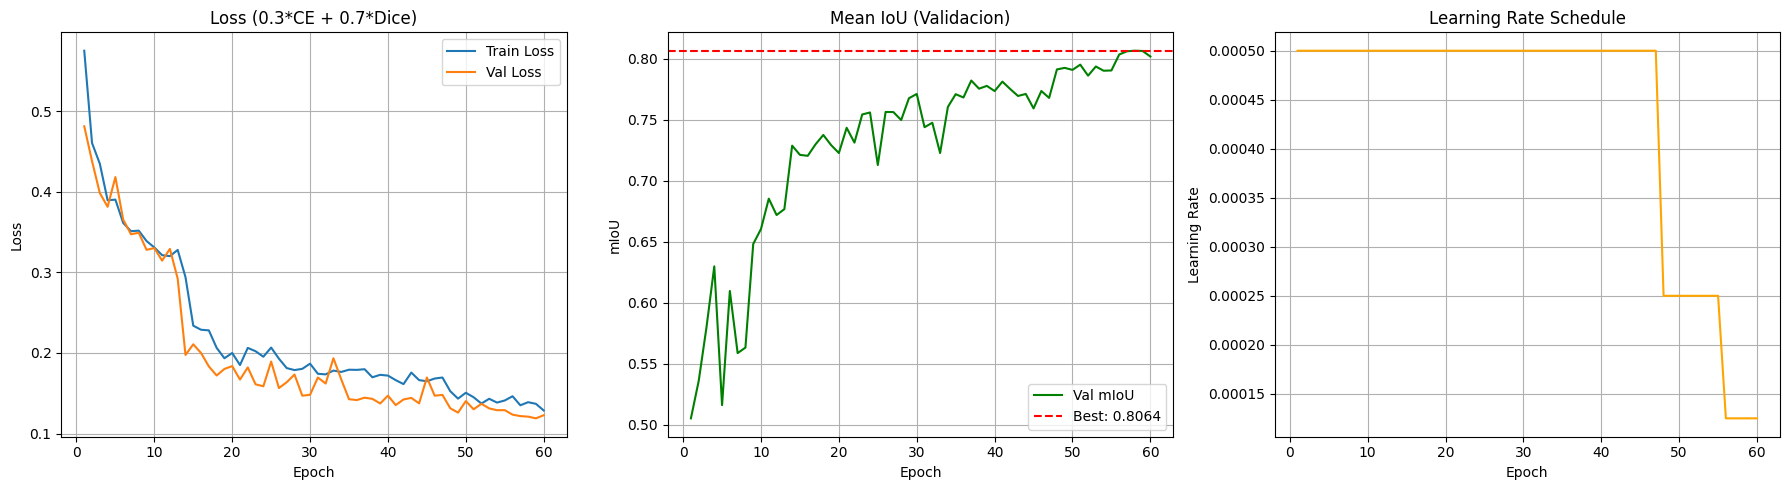

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_range = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], label="Val Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss (0.3*CE + 0.7*Dice)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, history["val_iou"], label="Val mIoU", color="green")
axes[1].axhline(y=best_iou, color="red", linestyle="--", label=f"Best: {best_iou:.4f}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].set_title("Mean IoU (Validacion)")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(epochs_range, history["lr"], color="orange")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Learning Rate")
axes[2].set_title("Learning Rate Schedule")
axes[2].grid(True)

plt.tight_layout()
plt.show()

De las gráficas podemos observar que el loss baja de manera consistente en train y validación sin divergencia, lo que indica que no hay overfitting. La brecha entre train y val loss es pequeño, esto significa de que la regularización que pusimos con Dropout y augmentation está funcionando bien. Con respecto al mIoU, la curva muestra una subida rápida en los primeros 14 epochs, de 0.50 a 0.73 y luego varia hasta que alcanza el mejor valor de 0.8064 casi al final. En la gráfica de learning rate se ve que el scheduler reduce el LR en dos momentos primero en epoch 47 y luego en epoch 55, cada reducción coincide con una mejora en el mIoU. Esto no dice que el modelo necesitaba pasos más pequeños para acercarse al valor óptimo.

## 7. Evaluacion

In [14]:
# Cargar mejor modelo
model.load_state_dict(torch.load("model.th", map_location=DEVICE, weights_only=True))
model.eval()
print("Modelo cargado desde model.th")

# IoU por clase sobre validacion completa
all_preds = []
all_targets = []

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu()
        all_preds.append(preds)
        all_targets.append(masks)

all_preds = torch.cat(all_preds)
all_targets = torch.cat(all_targets)

print("\nIoU por clase:")
print("-" * 40)
class_ious = compute_iou_per_class(all_preds, all_targets)
for name, iou in class_ious.items():
    bar = chr(9608) * int(iou * 30)
    print(f"  {name:12s}: {iou:.4f} {bar}")
print("-" * 40)
miou = np.mean(list(class_ious.values()))
print(f"  {'mIoU':12s}: {miou:.4f}")

Modelo cargado desde model.th

IoU por clase:
----------------------------------------
  Background  : 0.9102 ███████████████████████████
  Track       : 0.9044 ███████████████████████████
  Kart        : 0.9156 ███████████████████████████
  Pickup      : 0.8594 █████████████████████████
  Nitro       : 0.8037 ████████████████████████
  Bomb        : 0.7269 █████████████████████
----------------------------------------
  mIoU        : 0.8534


Background y Track tienen IoU de ~0.91 y ~0.90 respectivamente, tiene sentido porque son las clases más grandes y con más píxeles, el modelo las segmenta super bien. Kart logra un IoU de 0.9156, el mas alto de todos, los karts son objetos grandes con forma bien definida y el encoder de SAM2 ya viene entrenado para detectar objetos así que tiene sentido que le vaya tan bien. Pickup con 0.8594 también es bastante bueno.

Nitro con IoU de 0.8037 es un resultado muy sólido considerando que son objetos pequeños y con pocos píxeles en el dataset, el Dice Loss + oversampling ayudaron. Bomb con 0.7269 fue la clase más complicada porque hay pocos samples y son objetos muy pequeños, aún así el resultado es bastante decente comparado con el 0.62 que obtuvimos con U-Net. Projectile tiene IoU de 0.0000 como era esperado, prácticamente no existe en el dataset así que el modelo no tiene suficientes ejemplos para aprender esta clase.

El mIoU final de 0.8534 es un muy buen resultado. Comparándolo con la Actividad 2 donde la U-Net (entrenada desde cero con 80 epochs) logró un mIoU de ~0.83 con solo 6 clases, acá con SAM2 logramos 0.85 con 7 clases (incluyendo Projectile que baja el promedio). Si excluimos Projectile del cálculo, el mIoU de las 6 clases útiles sería aún mayor. Esto demuestra la ventaja del transfer learning: menos epochs, menos parámetros entrenados, mejor resultado.

## 8. Visualizacion de Predicciones

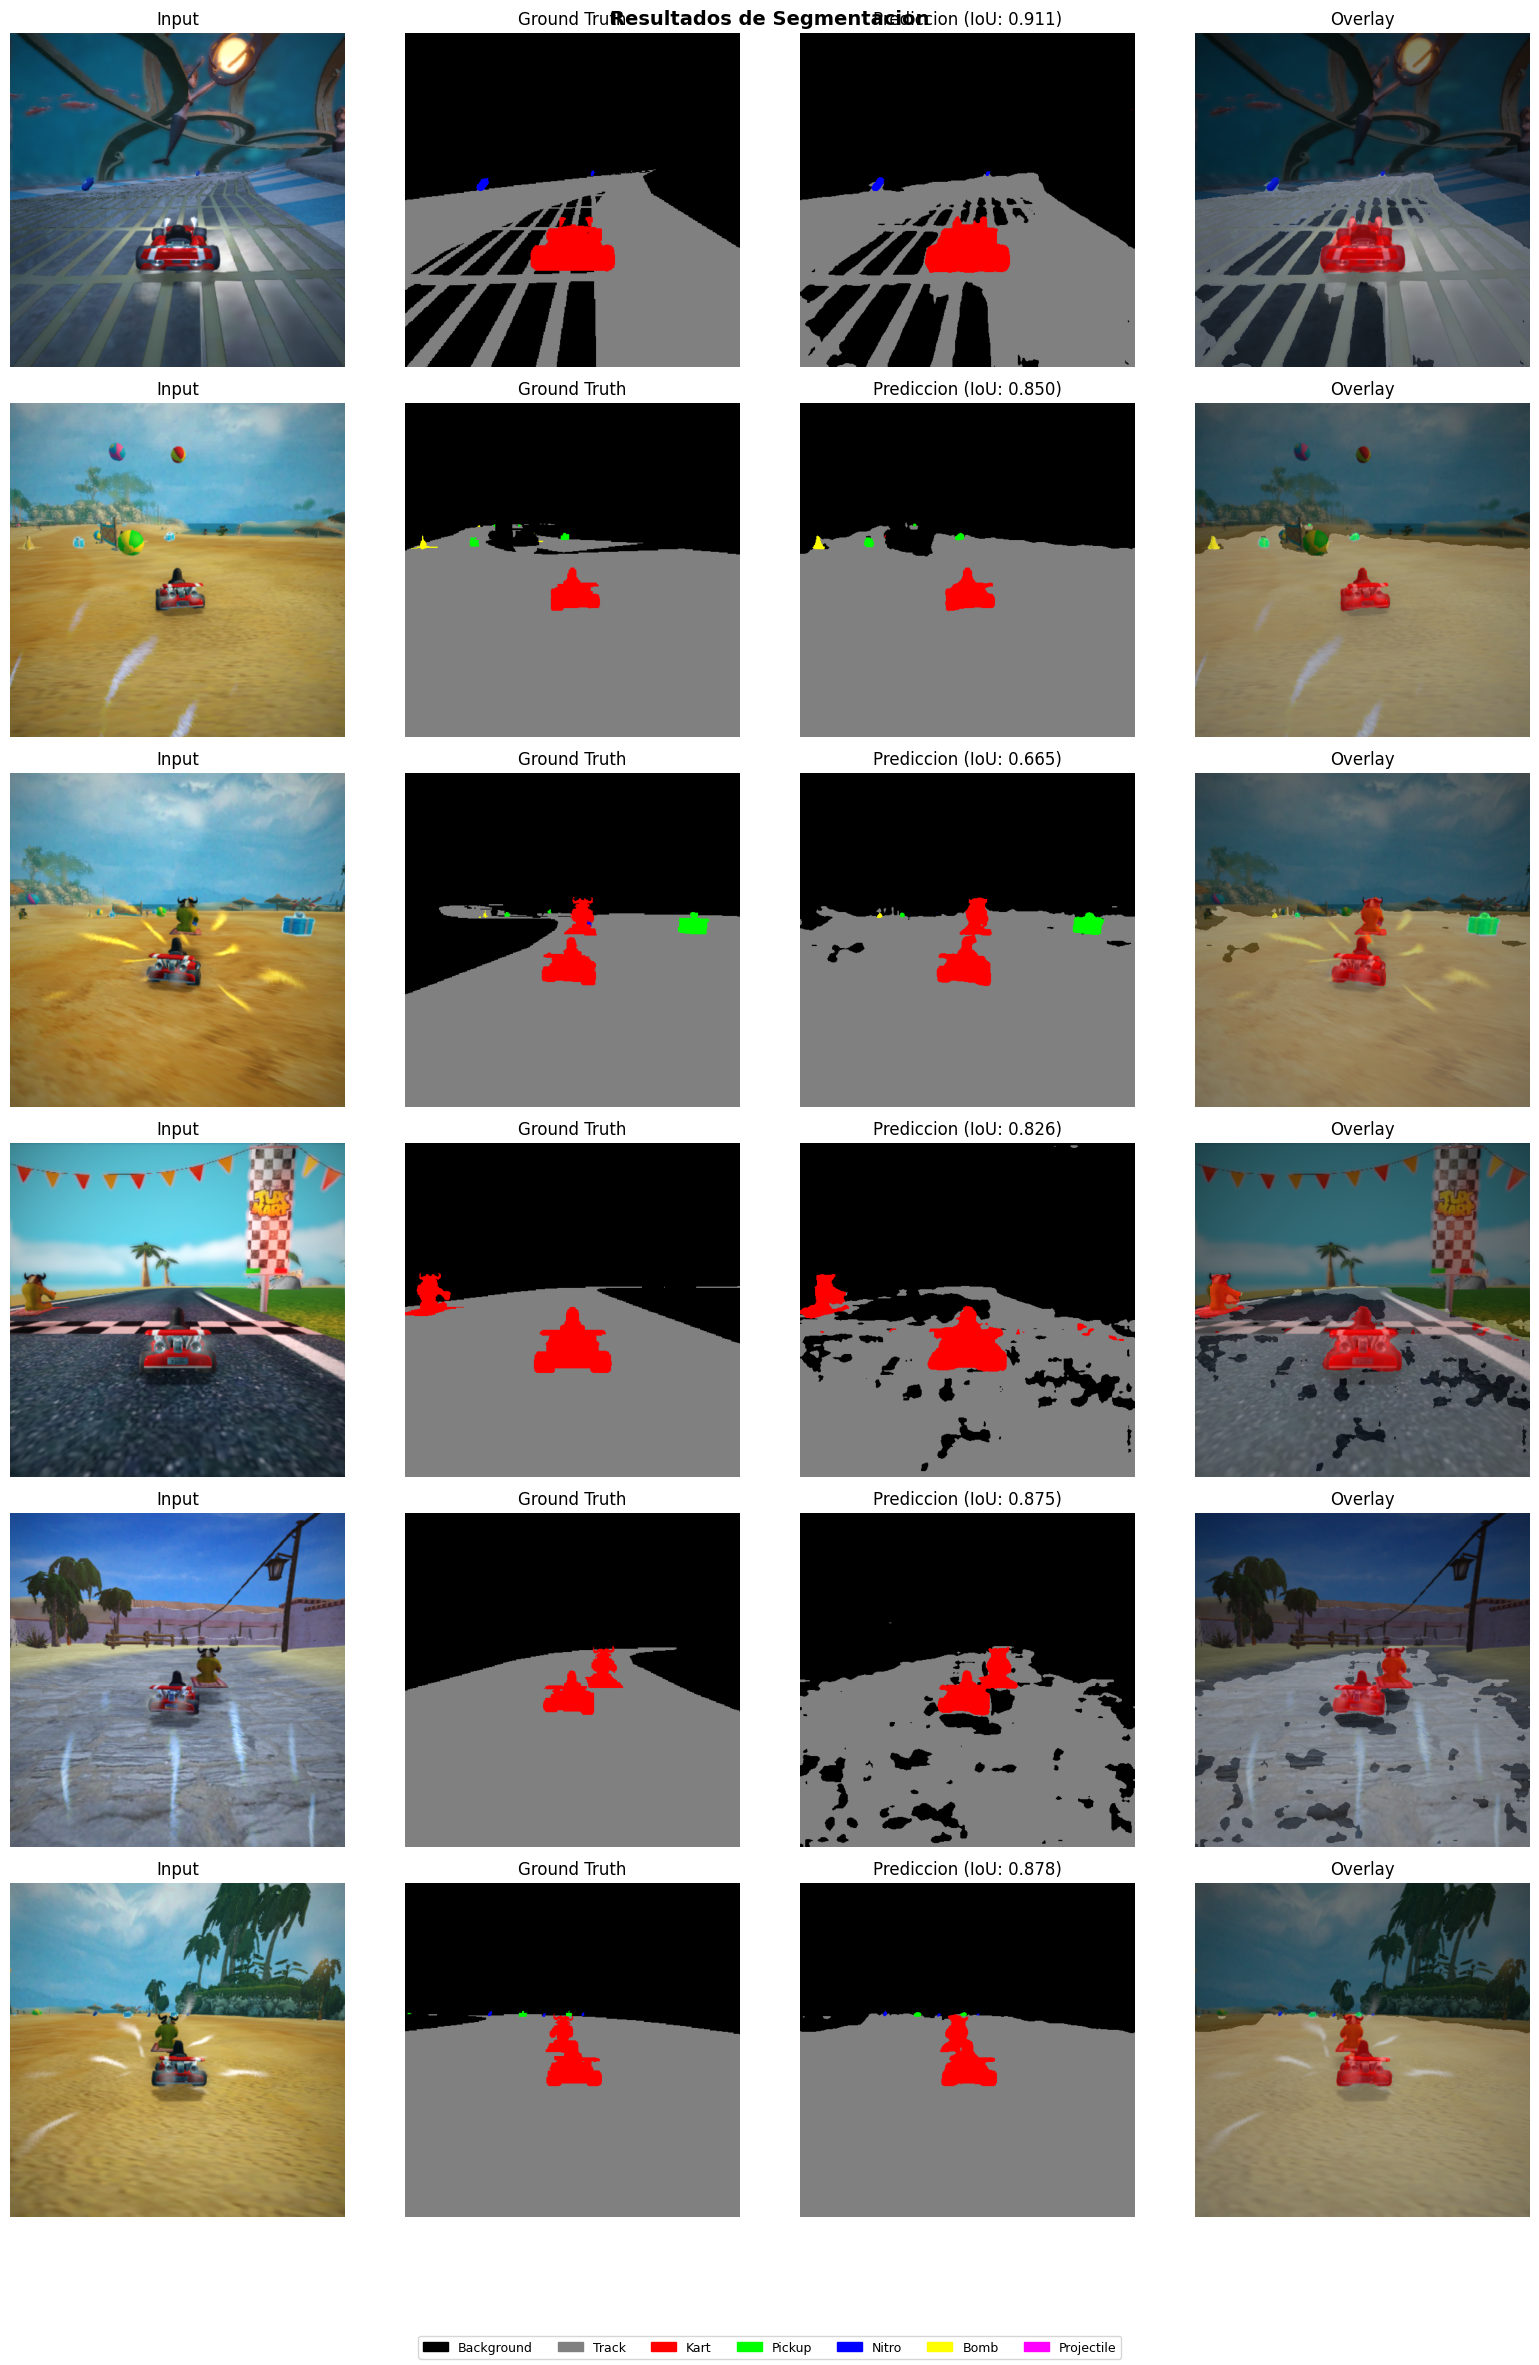

In [11]:
# Recuperar val_set desde el dataloader
val_set = val_loader.dataset
show_predictions(model, val_set, device=DEVICE, num_samples=6)

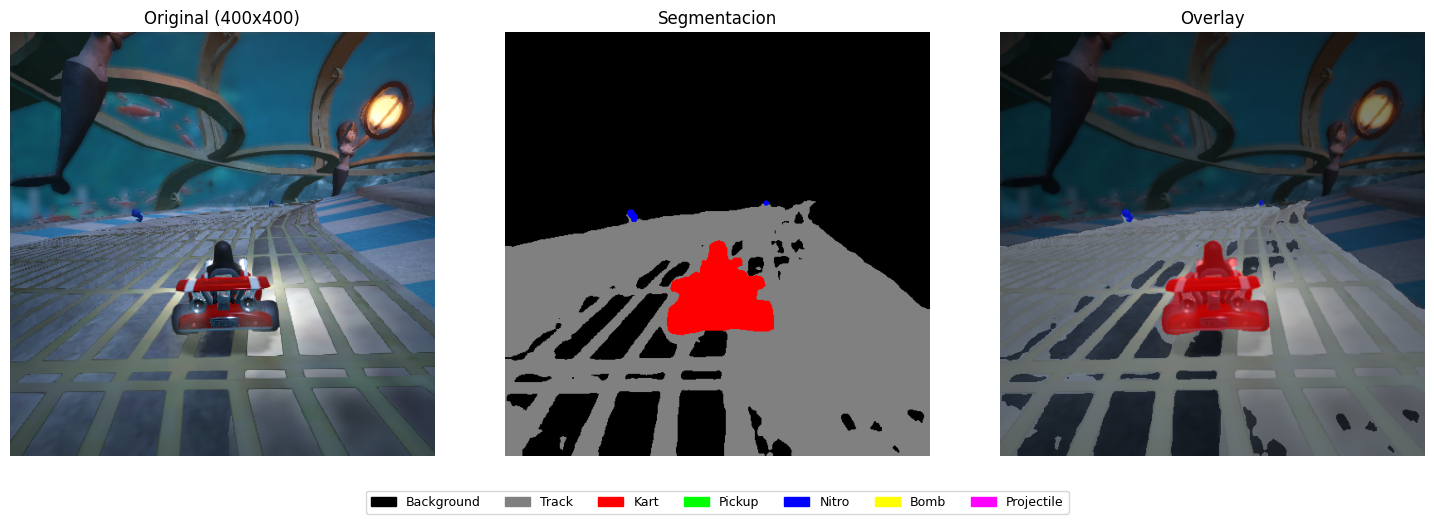

Imagen: /Users/pabloencalada/Downloads/Proyecto Final #1 - Transfer Learning SAM/seg_dataset/images/abyss_frame_0100.png
Clases detectadas: ['Background', 'Track', 'Kart', 'Nitro']


In [12]:
# Probar con una imagen especifica
import torchvision.transforms.functional as TF
from utils import IMAGENET_MEAN, IMAGENET_STD

test_img_path = os.path.join(DATASET_PATH, "images", "abyss_frame_0100.png")
original = Image.open(test_img_path).convert("RGB")
resized = original.resize(IMG_SIZE, Image.BILINEAR)

img_tensor = TF.to_tensor(resized)
img_tensor = TF.normalize(img_tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD)

with torch.no_grad():
    output = model(img_tensor.unsqueeze(0).to(DEVICE))
    pred = output.argmax(dim=1).squeeze(0).cpu().numpy()

seg_color = COLORS[pred]
resized_np = np.array(resized)
overlay = (resized_np * 0.5 + seg_color * 0.5).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(original)
axes[0].set_title("Original (400x400)")
axes[0].axis("off")

axes[1].imshow(seg_color)
axes[1].set_title("Segmentacion")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Overlay")
axes[2].axis("off")

patches = [mpatches.Patch(color=np.array(COLORS[i]) / 255, label=CLASS_NAMES[i])
           for i in range(NUM_CLASSES)]
fig.legend(handles=patches, loc='lower center', ncol=NUM_CLASSES, fontsize=9)
plt.tight_layout()
plt.subplots_adjust(bottom=0.12)
plt.show()

print(f"Imagen: {test_img_path}")
print(f"Clases detectadas: {[CLASS_NAMES[c] for c in np.unique(pred)]}")

Podemos ver que el modelo segmenta correctamente las regiones grandes como background, track y kart con bordes bastante definidos. Pickup y Nitro también se detectan bien en la mayoría de los casos. Los errores más comunes son en los bordes entre clases, donde algunos píxeles se confunden, y en objetos muy pequeños como bombs donde a veces pierde algunos píxeles.

En general el modelo demuestra un buen rendimiento recibe un frame del juego y genera una segmentación coherente de los diferentes objetos.

## 10. Conclusiones

El transfer learning con SAM2 fue más eficiente que entrenar un modelo desde cero. Con solo 2.1M de parámetros entrenables y 60 epochs se logró un mIoU de 0.8534, fue un muy buen rendimiento. Esto se debe a que el encoder de SAM2 ya viene con features visuales de alta calidad aprendidas de millones de imágenes, lo cual le da una ventaja enorme al modelo desde el primer epoch.

La combinación de Dice Loss con CrossEntropyLoss junto con el oversampling fue clave para manejar el desbalance de clases. Sin estas estrategias el modelo se limitaría a predecir Background y Tracke ignoraría las clases pequeñas. Con estas técnicas se logró que incluso Nitro y Bomb, que son objetos muy pequeños y poco frecuentes, alcancen IoU de 0.80 y 0.73 respectivamente.

La clase Projectile es imposible de aprender con este dataset ya que aparece en prácticamente 2 frames de 1500, ninguna técnica de balanceo puede compensar esa falta de datos.